#Steam Game Description Generator

This notebook trains GPT-2 to generate a description conditioned on Steam game genres. It uses a fixed random seed for more reproducible experiments. **The current source column is `long_description`**

## Reproducibility setup
Run this cell **before** splitting data, constructing the DataLoaders, or initializing the model. The same seed reduces random variation, although cross-hardware results may still differ.

In [1]:
import random as rand
import numpy as np
import torch

SEED_num = 42
rand.seed(SEED_num)
torch.manual_seed(SEED_num)

if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED_num)

print(f"Random seed: {SEED_num}")

Random seed: 42


Since one of the dataset takes too long to download, I imported **kagglehub package** to obtain the three datasets

In [2]:
import kagglehub

dataset_path = kagglehub.dataset_download(
    "mohamedtarek01234/steam-games-reviews-and-rankings"
)

print("Dataset location: ", dataset_path)

100%|██████████| 166M/166M [00:01<00:00, 113MB/s]

Extracting files...


Dataset location:  /root/.cache/kagglehub/datasets/mohamedtarek01234/steam-games-reviews-and-rankings/versions/1


In [3]:
import os

for file in os.listdir(dataset_path):
    print(file)

steam_game_reviews.csv
games_description.csv
games_ranking.csv


In [4]:
# Checking the shape of game descriptions and game rankings
import pandas as pd
from pathlib import Path

dataset_path = Path(dataset_path)

descriptions_df = pd.read_csv(
    dataset_path / "games_description.csv"
)

rankings_df = pd.read_csv(
    dataset_path / "games_ranking.csv"
)

print(f"Descriptions: {descriptions_df.shape}")
print(f"Rankings: {rankings_df.shape}")

Descriptions: (290, 13)
Rankings: (672, 4)


In [5]:
# Checking steam_game_reviews and using necessary columns
reviews_df = pd.read_csv(
    dataset_path / "steam_game_reviews.csv",
    usecols=["review", "game_name", "recommendation"],
    nrows = 1000000
)

print(f"Reviews: {reviews_df.shape}")
print(f"Unique games: {reviews_df["game_name"].nunique()}")

Reviews: (992153, 3)
Unique games: 242


### Inspecting columns to prepare for our training data

In [6]:
# Display column names and a preview of descriptions_df
print("Descriptions columns:", descriptions_df.columns.tolist())
display(descriptions_df[['name', 'short_description']].head())

# Display column names and a preview of rankings_df
print("\nRankings columns:", rankings_df.columns.tolist())
display(rankings_df[['game_name', 'genre']].head())

Descriptions columns: ['name', 'short_description', 'long_description', 'genres', 'minimum_system_requirement', 'recommend_system_requirement', 'release_date', 'developer', 'publisher', 'overall_player_rating', 'number_of_reviews_from_purchased_people', 'number_of_english_reviews', 'link']


,name,short_description
0,Black Myth: Wukong,Black Myth: Wukong is an action RPG rooted in ...
1,Counter-Strike 2,"For over two decades, Counter-Strike has offer..."
2,"Warhammer 40,000: Space Marine 2",Embody the superhuman skill and brutality of a...
3,Cyberpunk 2077,"Cyberpunk 2077 is an open-world, action-advent..."
4,ELDEN RING,THE CRITICALLY ACCLAIMED FANTASY ACTION RPG. R...



Rankings columns: ['game_name', 'genre', 'rank_type', 'rank']


,game_name,genre
0,Counter-Strike 2,Action
1,"Warhammer 40,000: Space Marine 2",Action
2,Cyberpunk 2077,Action
3,Black Myth: Wukong,Action
4,ELDEN RING,Action


In [7]:
# Check missing values
print(descriptions_df[
    ["short_description", "long_description"]
].isnull().sum())

# Check one long description
print(descriptions_df["long_description"].iloc[0])


short_description    13
long_description      0
dtype: int64
About This Game
							Black Myth: Wukong is an action RPG rooted in Chinese mythology. The story is based on Journey to the West, one of the Four Great Classical Novels of Chinese literature. You shall set out as the Destined One to venture into the challenges and marvels ahead, to uncover the obscured truth beneath the veil of a glorious legend from the past.• Explore a Land of Vast Wonders"A world unseen, where wonders gleam,And with each stride, a new scene streams."Enter a fascinating realm filled with the wonders and discoveries of ancient Chinese mythology!As the Destined One, you shall traverse an array of breathtaking and distinctive landscapes from the classic tale, composing an epic of adventure that is seen anew.• Confront Mighty Foes, Old and New"Heroic Monkey, might and fame, Adversaries rise, to test his name."One of the major highlights of Journey to the West is its diverse cast of adversaries, each with their

In [8]:
# Checking to see either we should use long_description or short_description based on average
average_long = descriptions_df["long_description"].str.split().str.len().mean()
average_short = descriptions_df['short_description'].str.split().str.len().mean()

print(f"Average for long_description: {average_long}")
print(f"Average for short_description: {average_short}")


Average for long_description: 324.12068965517244
Average for short_description: 35.68953068592058


# Training Data

In [9]:
# Create our training DataFrame
training_df = descriptions_df[
    ["name", "genres", "long_description"]
].copy()

In [10]:
# Checking for missing data
print(training_df.isnull().sum())
print("Duplicate games:", training_df["name"].duplicated().sum())

name                0
genres              0
long_description    0
dtype: int64
Duplicate games: 0


In [11]:
# Checking for duplicate games
print("Duplicate games:", training_df["name"].duplicated().sum())

print("Duplicate descriptions:",
      training_df["long_description"].duplicated().sum())

Duplicate games: 0
Duplicate descriptions: 0


In [12]:
# Checking for empty descriptions
print("Empty descriptions:",
      (training_df["long_description"].str.strip() == "").sum())

Empty descriptions: 0


In [13]:
#Inspecting text
print(training_df["long_description"].iloc[0])

About This Game
							Black Myth: Wukong is an action RPG rooted in Chinese mythology. The story is based on Journey to the West, one of the Four Great Classical Novels of Chinese literature. You shall set out as the Destined One to venture into the challenges and marvels ahead, to uncover the obscured truth beneath the veil of a glorious legend from the past.• Explore a Land of Vast Wonders"A world unseen, where wonders gleam,And with each stride, a new scene streams."Enter a fascinating realm filled with the wonders and discoveries of ancient Chinese mythology!As the Destined One, you shall traverse an array of breathtaking and distinctive landscapes from the classic tale, composing an epic of adventure that is seen anew.• Confront Mighty Foes, Old and New"Heroic Monkey, might and fame, Adversaries rise, to test his name."One of the major highlights of Journey to the West is its diverse cast of adversaries, each with their unique strengths.As the Destined One, you will encounter pow

In [14]:
#Checking for duplicates and empty descriptions
print("Duplicate descriptions:",
      training_df["long_description"].duplicated().sum())

print("Empty descriptions:",
      (training_df["long_description"].str.strip() == "").sum())

Duplicate descriptions: 0
Empty descriptions: 0


In [15]:
# Cleaning the text


import re

def clean_description(text):
    # Add space after punctuation when followed by a letter
    text = re.sub(r'([.!?])([A-Za-z])', r'\1 \2', text)

    # Add space after commas when followed by a letter
    text = re.sub(r'([,;:])([A-Za-z])', r'\1 \2', text)

    # Add space before bullet points
    text = re.sub(r'([^\s])•', r'\1 •', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text)

    # Add space after a closing quote that follows sentence punctuation
    text = re.sub(r'([.!?]")([A-Za-z])', r'\1 \2', text)

    # Add space before an opening quotation mark
    text = re.sub(r'([A-Za-z])(")', r'\1 \2', text)

    return text.strip()



In [16]:
#Checking to see if the text is cleaned now
original = training_df["long_description"].iloc[0]

cleaned = clean_description(original)

print(cleaned[:1000])


About This Game Black Myth: Wukong is an action RPG rooted in Chinese mythology. The story is based on Journey to the West, one of the Four Great Classical Novels of Chinese literature. You shall set out as the Destined One to venture into the challenges and marvels ahead, to uncover the obscured truth beneath the veil of a glorious legend from the past. • Explore a Land of Vast Wonders "A world unseen, where wonders gleam, And with each stride, a new scene streams." Enter a fascinating realm filled with the wonders and discoveries of ancient Chinese mythology! As the Destined One, you shall traverse an array of breathtaking and distinctive landscapes from the classic tale, composing an epic of adventure that is seen anew. • Confront Mighty Foes, Old and New "Heroic Monkey, might and fame, Adversaries rise, to test his name." One of the major highlights of Journey to the West is its diverse cast of adversaries, each with their unique strengths. As the Destined One, you will encounter p

In [17]:
training_df["clean_description"] = (
    training_df["long_description"].apply(clean_description)
)

In [18]:
training_df[
    ["name", "genres", "clean_description"]
].head()

,name,genres,clean_description
0,Black Myth: Wukong,"['Mythology', 'Action RPG', 'Action', 'RPG', '...",About This Game Black Myth: Wukong is an actio...
1,Counter-Strike 2,"['FPS', 'Shooter', 'Multiplayer', 'Competitive...","About This Game For over two decades, Counter-..."
2,"Warhammer 40,000: Space Marine 2","['Warhammer 40K', 'Action', 'Third-Person Shoo...",About This Game Embody the superhuman skill an...
3,Cyberpunk 2077,"['Cyberpunk', 'Open World', 'Nudity', 'RPG', '...",About This Game Cyberpunk 2077 is an open-worl...
4,ELDEN RING,"['Souls-like', 'Dark Fantasy', 'Open World', '...",About This Game THE CRITICALLY ACCLAIMED FANTA...


In [19]:
word_counts = training_df["clean_description"].str.split().str.len()

print("Average words:", word_counts.mean())
print("Minimum words:", word_counts.min())
print("Maximum words:", word_counts.max())

Average words: 330.28620689655173
Minimum words: 3
Maximum words: 1404


# Comparing different tokenizers

In [20]:

import tiktoken
from transformers import AutoTokenizer

enc = tiktoken.get_encoding("gpt2")
tokenizer = AutoTokenizer.from_pretrained(
    "openai-community/gpt2"
)

text = "Black Myth: Wukong is an action RPG."

tiktoken_ids = enc.encode(text)
huggingface_ids = tokenizer.encode(
    text,
    add_special_tokens=False
)

print("tiktoken:", tiktoken_ids)
print("Hugging Face:", huggingface_ids)

print("Same token IDs?",
      tiktoken_ids == huggingface_ids)


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

tiktoken: [9915, 18900, 25, 370, 46654, 318, 281, 2223, 12909, 13]
Hugging Face: [9915, 18900, 25, 370, 46654, 318, 281, 2223, 12909, 13]
Same token IDs? True


# Using tiktoken Package

Initalize tiktoken

In [21]:
import tiktoken

enc = tiktoken.get_encoding("gpt2")

Tokenize one long description

In [22]:
description = training_df["clean_description"].iloc[0]

tokens = enc.encode(description)

print("Word count:", len(description.split()))
print("Token count:", len(tokens))

Word count: 344
Token count: 427


Tokenize all descriptions

In [23]:
training_df["token_count"] = training_df["clean_description"].apply(
    lambda text: len(enc.encode(text))
)

In [24]:
print("Average tokens:", training_df["token_count"].mean())
print("Maximum tokens:", training_df["token_count"].max())

print("Descriptions over 512 tokens:",
      (training_df["token_count"] > 512).sum())

print("Descriptions over 1024 tokens:",
      (training_df["token_count"] > 1024).sum())

Average tokens: 430.2758620689655
Maximum tokens: 2907
Descriptions over 512 tokens: 88
Descriptions over 1024 tokens: 8


In [25]:
# Training example using tiktoken

genres = training_df["genres"].iloc[0]
description = training_df["clean_description"].iloc[0]

prompt = f"Genres: {genres}\nDescription:"

full_text = prompt + " " + description

tokens = enc.encode(full_text)

print("Genres:", genres)
print("Prompt tokens:", len(enc.encode(prompt)))
print("Total tokens:", len(tokens))


Genres: ['Mythology', 'Action RPG', 'Action', 'RPG', 'Souls-like', 'Combat', 'Story Rich', 'Singleplayer', 'Drama', 'Action-Adventure', 'Dark Fantasy', 'Atmospheric', 'Adventure', '3D', 'Fantasy', 'Hack and Slash', 'Third Person', 'Difficult', 'Music', 'Violent']
Prompt tokens: 86
Total tokens: 513


Adding the end-of-text token
* When training GPT-2, we want the model to recognize when a description is finished


In [26]:
eos_token = enc.eot_token

print("End-of-text token ID:", eos_token)

End-of-text token ID: 50256


In [27]:
tokens_with_eos = tokens + [eos_token]

print("Original tokens:", len(tokens))
print("Tokens with EOS:", len(tokens_with_eos))
print("Last token:", tokens_with_eos[-1])

Original tokens: 513
Tokens with EOS: 514
Last token: 50256


# Create a Reuseable Token Function

Defining the function

In [28]:
def tokenize_example(genres, description, max_length=1024):
    prompt = f"Genres: {genres}\nDescription:"

    prompt_tokens = enc.encode(prompt)
    description_tokens = enc.encode(" " + description)

    available_space = max_length - len(prompt_tokens) - 1

    # Truncate the description to fit
    description_tokens = description_tokens[:available_space]

    # Combine prompt + description + EOS
    input_ids = prompt_tokens + description_tokens + [eos_token]

    # Create label
    labels = [-100] * len(prompt_tokens)
    labels = labels + description_tokens + [eos_token]

    return {
        "input_ids": input_ids,
        "labels": labels
    }


Testing the function out with an example

In [31]:
tokens = tokenize_example(
    training_df["genres"].iloc[0],
    training_df["clean_description"].iloc[0]
)

# Access 'input_ids' inside the returned dictionary to get the token list
print("Total tokens:", len(tokens["input_ids"]))
print("Last token:", tokens["input_ids"][-1])

Total tokens: 514
Last token: 50256


# Creating Training Labels

Understanding what labels do
* If the model receives text that includes list of genres and obtains a description, we want want GPT-2 to use the genres as context, but **calculate training loss only on the description**, not the genre prompt
* In PyTorch, we can use -100 to tell GPT-2's loss function to ignore certain token positions.

In [32]:
#Example

#prompt_tokens = [10, 20, 30]
#description_tokens = [40, 50, 60]

labels = [-100, -100, -100, 40, 50, 60]

In [33]:

# Ignore the genre prompt when calculating loss

#labels = [-100] * len(prompt_tokens)

# Add the description tokens and EOS token

#labels = labels + description_tokens + [eos_token]


Why we need **labels**?

* Python executes the function from top to bottom. We first prepare the tokens, then create the model inputs and training labels using those tokens.

* The -100 values tell the loss function to ignore the genre prompt during training. GPT-2 will still receive the genres as input

In [34]:
# Running this example with the updated tokenizer function

result = tokenize_example(
    training_df["genres"].iloc[0],
    training_df["clean_description"].iloc[0]
)

print("Input length:", len(result["input_ids"]))
print("Labels length:", len(result["labels"]))
print("First 10 labels:", result["labels"][:10])
print("Last label:", result["labels"][-1])

Input length: 514
Labels length: 514
First 10 labels: [-100, -100, -100, -100, -100, -100, -100, -100, -100, -100]
Last label: 50256


# Creating a PyTorch Dataset

In [35]:
# Import the dataset
from torch.utils.data import Dataset

# Create a Dataset class
class SteamDataset(Dataset):
  def __init__(self, dataframe):
    self.dataframe = dataframe

  def __len__(self):
    return len(self.dataframe)

  def __getitem__(self, idx):
    row = self.dataframe.iloc[idx]

    tokens = tokenize_example(
        row["genres"],
        row["clean_description"]
    )

    return tokens

In [36]:
#Testing out this dataset
steam_dataset = SteamDataset(training_df)

example = steam_dataset[0]

print("Keys:", example.keys())
print("Input length:", len(example["input_ids"]))
print("Labels length:", len(example["labels"]))

Keys: dict_keys(['input_ids', 'labels'])
Input length: 514
Labels length: 514


# Understanding PyTorch tensors

In [37]:
# Converting input_ids into a tensor
example = steam_dataset[0]

input_tensor = torch.tensor(
    example["input_ids"],
    dtype=torch.long
)

print("Tensor shape:", input_tensor.shape)
print("Tensor type:", input_tensor.dtype)


Tensor shape: torch.Size([514])
Tensor type: torch.int64


In [38]:
# Converting labels into a tensor
example = steam_dataset[0]

label_tensor = torch.tensor(
    example["labels"],
    dtype = torch.long
)

print("Tensor shape:", input_tensor.shape)
print("Tensor type:", input_tensor.dtype)

Tensor shape: torch.Size([514])
Tensor type: torch.int64


In [39]:
#Checking whether the labels correctly ignore the genre prompt
print("First 10 input tokens:", input_tensor[:10])
print("First 10 label tokens:", label_tensor[:10])

First 10 input tokens: tensor([13746,   411,    25, 37250, 41444,  1435,  3256,   705, 12502, 12909])
First 10 label tokens: tensor([-100, -100, -100, -100, -100, -100, -100, -100, -100, -100])


Why should the first 10 values of label_tensor all be -100, while the first 10 values of input_tensor are normal token IDs?

* We want GPT-2 to learn how to generate the correct next tokens in a game description based on the genres provided.

#  Creating Batches with PyTorch

In [40]:

import torch
from torch.nn.utils.rnn import pad_sequence

game_a = torch.tensor([10, 20, 30, 40])
game_b = torch.tensor([50, 60])

batch = pad_sequence(
    [game_a, game_b],
    batch_first=True,
    padding_value=0
)

print(batch)
print("Batch shape:", batch.shape)


tensor([[10, 20, 30, 40],
        [50, 60,  0,  0]])
Batch shape: torch.Size([2, 4])


In [41]:


import torch
from torch.nn.utils.rnn import pad_sequence

def collate_fn(batch):
    # Convert token lists into PyTorch tensors
    input_ids = [
        torch.tensor(item["input_ids"], dtype=torch.long)
        for item in batch
    ]

    labels = [
        torch.tensor(item["labels"], dtype=torch.long)
        for item in batch
    ]

    # Create attention masks before padding
    attention_masks = [
        torch.ones_like(ids)
        for ids in input_ids
    ]

    # Pad input IDs
    padded_inputs = pad_sequence(
        input_ids,
        batch_first=True,
        padding_value=eos_token
    )

    # Pad labels
    padded_labels = pad_sequence(
        labels,
        batch_first=True,
        padding_value=-100
    )

    # Pad attention masks
    padded_masks = pad_sequence(
        attention_masks,
        batch_first=True,
        padding_value=0
    )

    # Return the batch
    return {
        "input_ids": padded_inputs,
        "labels": padded_labels,
        "attention_mask": padded_masks
    }




In [42]:
batch = collate_fn([
    steam_dataset[0],
    steam_dataset[1]
])

print("Input shape:", batch["input_ids"].shape)
print("Labels shape:", batch["labels"].shape)
print("Attention mask shape:", batch["attention_mask"].shape)

Input shape: torch.Size([2, 514])
Labels shape: torch.Size([2, 514])
Attention mask shape: torch.Size([2, 514])


# Splitting the Data

In [43]:
from sklearn.model_selection import train_test_split


train_df, val_df = train_test_split(
    training_df,
    test_size=0.2,
    random_state=SEED_num,
    shuffle=True
)

print("Training games:", len(train_df))
print("Validation games:", len(val_df))

Training games: 232
Validation games: 58


# Creating the PyTorch DataLoaders

In [44]:

train_dataset = SteamDataset(train_df)
val_dataset = SteamDataset(val_df)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))


Training examples: 232
Validation examples: 58


In [45]:
from torch.utils.data import DataLoader


train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle = False,
    collate_fn = collate_fn
)


In [46]:
batch = next(iter(train_loader))

print("Input shape:", batch["input_ids"].shape)
print("Labels shape:", batch["labels"].shape)
print("Attention mask shape:", batch["attention_mask"].shape)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Input shape: torch.Size([4, 1024])
Labels shape: torch.Size([4, 1024])
Attention mask shape: torch.Size([4, 1024])
Training batches: 58
Validation batches: 15


# Loading the pretrained GPT-2

In [47]:
from transformers import GPT2LMHeadModel


model_name = "openai-community/gpt2"

model = GPT2LMHeadModel.from_pretrained(model_name)

model.config.pad_token_id = eos_token

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print("Using device:", device)

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Using device: cuda


In [48]:
from torch.optim import AdamW

learning_rate = 2e-5

optimizer = AdamW(
    model.parameters(),
    lr=learning_rate
)

In [49]:
# Train GPT-2 for one epoch

model.train()

# Track the total training loss
total_loss = 0

# Loop through all training batches
for batch in train_loader:

    # Step 1: Clear previous gradients
    optimizer.zero_grad()

    # Step 2: Move tensors to GPU or CPU
    input_ids = batch["input_ids"].to(device)
    labels = batch["labels"].to(device)
    attention_mask = batch["attention_mask"].to(device)

    # Step 3: Forward pass
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        labels=labels
    )

    # Step 4: Calculate loss
    loss = outputs.loss

    # Step 5: Backpropagation
    loss.backward()

    # Step 6: Update model weights
    optimizer.step()

    # Step 7: Track training loss
    total_loss += loss.item()

# Step 8: Calculate average loss
average_loss = total_loss / len(train_loader)

print("Average training loss:", average_loss)


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Average training loss: 3.702637532661701


In [50]:

# Set GPT-2 to evaluation mode
model.eval()

total_val_loss = 0

# Disable gradient calculations
with torch.no_grad():
    for batch in val_loader:
        input_ids = batch["input_ids"].to(device)
        labels = batch["labels"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        # Forward pass
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        # Track validation loss
        loss = outputs.loss
        total_val_loss += loss.item()

# Calculate average validation loss
average_val_loss = total_val_loss / len(val_loader)

print("Average training loss:", average_loss)
print("Average validation loss:", average_val_loss)


Average training loss: 3.702637532661701
Average validation loss: 3.5971890926361083


In [51]:

# Epoch 2: Training
model.train()
total_loss = 0

for batch in train_loader:
    optimizer.zero_grad()

    input_ids = batch["input_ids"].to(device)
    labels = batch["labels"].to(device)
    attention_mask = batch["attention_mask"].to(device)

    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        labels=labels
    )

    loss = outputs.loss
    loss.backward()
    optimizer.step()

    total_loss += loss.item()

average_loss = total_loss / len(train_loader)

print("Epoch 2 training loss:", average_loss)


Epoch 2 training loss: 3.52640190206725


In [52]:

# Epoch 2: Validation

# Step 1: Set the model to evaluation mode
model.eval()

# Step 2: Reset validation loss
total_val_loss = 0

# Step 3: Disable gradient calculations
with torch.no_grad():

    # Step 4: Loop through validation batches
    for batch in val_loader:

        # Move tensors to GPU or CPU
        input_ids = batch["input_ids"].to(device)
        labels = batch["labels"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        # Forward pass
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        # Calculate validation loss
        loss = outputs.loss

        # Accumulate validation loss
        total_val_loss += loss.item()

# Step 5: Calculate average validation loss
average_val_loss = total_val_loss / len(val_loader)

# Step 6: Display Epoch 2 results
print("Epoch 2 training loss:", average_loss)
print("Epoch 2 validation loss:", average_val_loss)


Epoch 2 training loss: 3.52640190206725
Epoch 2 validation loss: 3.580172650019328


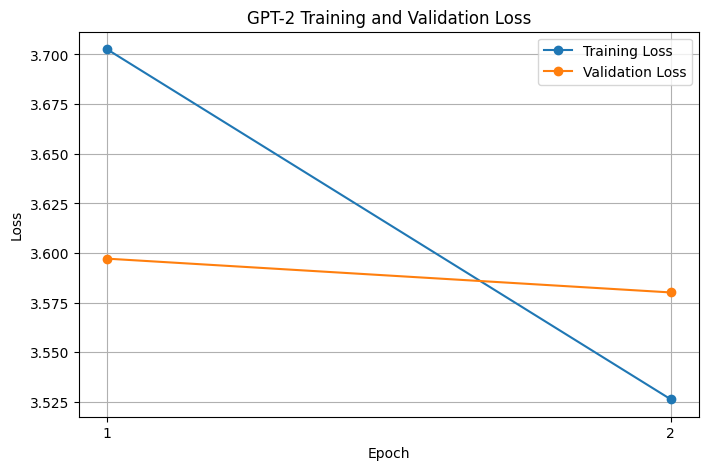

In [53]:

import matplotlib.pyplot as plt

# Training results from Epoch 1 and Epoch 2
epochs = [1, 2]

training_losses = [
    3.702637532661701,
    3.52640190206725
]

validation_losses = [
    3.5971890926361083,
    3.580172650019328
]

# Create the line graph
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    training_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    validation_losses,
    marker="o",
    label="Validation Loss"
)

plt.title("GPT-2 Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.show()


# Generating a Steam Game Description

In [54]:

# Switch GPT-2 to evaluation mode
model.eval()

# Choose the genres
genres = "Action RPG, Mythology, Adventure"

# Create the prompt
prompt = f"Genres: {genres}\nDescription:"

# Tokenize the prompt
input_ids = torch.tensor(
    [enc.encode(prompt)],
    dtype=torch.long
).to(device)

# Generate new text
with torch.no_grad():
    generated_ids = model.generate(
        input_ids=input_ids,
        max_new_tokens=150,
        do_sample=True,
        temperature=0.8,
        top_p=0.9,
        pad_token_id=eos_token,
        eos_token_id=eos_token
    )

# Decode only the generated description
new_tokens = generated_ids[0, input_ids.shape[1]:].tolist()
description = enc.decode(new_tokens)

print("Genres:", genres)
print("Generated description:", description)


Genres: Action RPG, Mythology, Adventure
Generated description:  About This Game The story of the story of The Last Knight of the Sword, a story of the sword that was forged by the Great Knight of the Empire. This story follows a young man named F.S. who, after a long war, finds himself in the middle of the land with a band of bandits. The fate of his friend rests on him. The story begins with him fighting against the bandits, who attack him in the name of the Great Knights of the Empire, in which he must fight to protect his father's family. From there, his quest begins. The Legend of The Last Knight of the Sword, a tale of the sword forged by the Great Knight of the Empire. From here, F.S. must lead a


In [55]:
# Switch GPT-2 to evaluation mode
model.eval()

# Choose the genres
genres = "Action RPG, Mythology, Adventure"

# Create the prompt
prompt = f"Genres: {genres}\nDescription:"

# Tokenize the prompt
input_ids = torch.tensor(
    [enc.encode(prompt)],
    dtype=torch.long
).to(device)

# Generate new text
with torch.no_grad():
    generated_ids = model.generate(
        input_ids=input_ids,
        max_new_tokens=150,
        do_sample=True,
        temperature=0.8,
        top_p=0.9,
        repetition_penalty=1.2,
        no_repeat_ngram_size=3,
        pad_token_id=eos_token,
        eos_token_id=eos_token
    )

# Decode only the generated description
new_tokens = generated_ids[0, input_ids.shape[1]:].tolist()
description = enc.decode(new_tokens)

print("Genres:", genres)
print("Generated description:", description)



Genres: Action RPG, Mythology, Adventure
Generated description:  About This Game You've been given a name and you're finally ready to join the ranks of your beloved leader. With no choice but to go down in history as one who could have saved humanity from extinction by taking control over an ancient alien civilization with magic that has brought it prosperity for generations… what better way to set yourself apart than through this epic journey? Choose between three paths before embarking on their mysterious quest! Set off against time or face death at any point along its path – fight enemies across every continent they come into contact (from The Black Rose Canyon , Ancient Ruins , Beyond ), battle mythical creatures like those seen throughout Time-Lost Legends . Or turn up alone amid chaos due all too common ways such Ascent's mysteries can only be


In [56]:
# Switch GPT-2 to evaluation mode
model.eval()

# Choose the genres
genres = "Action RPG, Mythology, Adventure"

# Create the prompt
prompt = f"Genres: {genres}\nDescription:"

# Tokenize the prompt
input_ids = torch.tensor(
    [enc.encode(prompt)],
    dtype=torch.long
).to(device)

# Generate new text
with torch.no_grad():
    generated_ids = model.generate(
        input_ids=input_ids,
        max_new_tokens=200,
        do_sample=True,
        temperature=0.7,
        top_p=0.9,
        repetition_penalty=1.1,
        no_repeat_ngram_size=3,
        pad_token_id=eos_token,
        eos_token_id=eos_token
    )

# Decode only the generated description
new_tokens = generated_ids[0, input_ids.shape[1]:].tolist()
description = enc.decode(new_tokens)

print("Genres:", genres)
print("Generated description:", description)

Genres: Action RPG, Mythology, Adventure
Generated description:  About This Game A fantasy adventure set in the world of Dromund Kaas. The hero is a young boy who has fallen into madness and becomes an evil monster that needs to be defeated with his own power! Will you fight against this threat or face your demons? Or will he become too powerful for life as long as others stand by him!?

<|endoftext|>


In [57]:

# Switch GPT-2 to evaluation mode
model.eval()

# Choose genres
genres = "Action RPG, Mythology, Adventure"

# Create the prompt
prompt = f"Genres: {genres}\nDescription:"

# Convert prompt into tokens
input_ids = torch.tensor(
    [enc.encode(prompt)],
    dtype=torch.long
).to(device)

# Generate a game description
with torch.no_grad():
    generated_ids = model.generate(
        input_ids=input_ids,
        max_new_tokens=200,
        do_sample=True,
        temperature=0.7,
        top_p=0.9,
        repetition_penalty=1.1,
        no_repeat_ngram_size=3,
        pad_token_id=eos_token,
        eos_token_id=eos_token
    )

# Extract only the generated tokens
new_tokens = generated_ids[0, input_ids.shape[1]:].tolist()

# Remove the end-of-text token and anything after it
if eos_token in new_tokens:
    new_tokens = new_tokens[:new_tokens.index(eos_token)]

# Convert tokens back into text
description = enc.decode(new_tokens).strip()

# Display results
print("Genres:", genres)
print("Generated description:", description)


Genres: Action RPG, Mythology, Adventure
Generated description: About This Game The Legend of Zelda™: Ocarina Of Time™ is a massive world in the depths of time. A vast forest and endless forests are its domain as you explore it with friends or strangers alike to create your own unique story within this beloved series by creating an expansive storyline that blends traditional JRPGs like Metroid Prime's classic games such Asuna & Samus Returns®, Super Smash Bros., Donkey Kong Country 2 and more! Explore different worlds from across eras including ancient dungeons hidden under mysterious trees; save islands where legendary heroes have passed away while searching for their lost comrades who might lead them back home once again - each one being full of surprises at every turn... But beware – there will always be enemies waiting on top of any corner… So don't let anyone fool around just yet -- discover new locations throughout Link's journey through Hyrule Island before long--and conquer the

In [58]:
# Switch GPT-2 to evaluation mode
model.eval()

# Choose genres
genres = "Horror, Survival, Psychological"

# Create the prompt
prompt = f"Genres: {genres}\nDescription:"

# Convert prompt into tokens
input_ids = torch.tensor(
    [enc.encode(prompt)],
    dtype=torch.long
).to(device)

# Generate a game description
with torch.no_grad():
    generated_ids = model.generate(
        input_ids=input_ids,
        max_new_tokens=200,
        do_sample=True,
        temperature=0.7,
        top_p=0.9,
        repetition_penalty=1.1,
        no_repeat_ngram_size=3,
        pad_token_id=eos_token,
        eos_token_id=eos_token
    )

# Extract only the generated tokens
new_tokens = generated_ids[0, input_ids.shape[1]:].tolist()

# Remove the end-of-text token and anything after it
if eos_token in new_tokens:
    new_tokens = new_tokens[:new_tokens.index(eos_token)]

# Convert tokens back into text
description = enc.decode(new_tokens).strip()

# Display results
print("Genres:", genres)
print("Generated description:", description)

Genres: Horror, Survival, Psychological
Generated description: About This Game Explore an abandoned village with no sign of life. It is as if the only thing you can do now are hunt down a stray fox and then let it go into your backyard to die… or something like that!


In [59]:
# Switch GPT-2 to evaluation mode
model.eval()

# Choose genres
genres = "Simulation, Farming, Casual"

# Create the prompt
prompt = f"Genres: {genres}\nDescription:"

# Convert prompt into tokens
input_ids = torch.tensor(
    [enc.encode(prompt)],
    dtype=torch.long
).to(device)

# Generate a game description
with torch.no_grad():
    generated_ids = model.generate(
        input_ids=input_ids,
        max_new_tokens=200,
        do_sample=True,
        temperature=0.7,
        top_p=0.9,
        repetition_penalty=1.1,
        no_repeat_ngram_size=3,
        pad_token_id=eos_token,
        eos_token_id=eos_token
    )

# Extract only the generated tokens
new_tokens = generated_ids[0, input_ids.shape[1]:].tolist()

# Remove the end-of-text token and anything after it
if eos_token in new_tokens:
    new_tokens = new_tokens[:new_tokens.index(eos_token)]

# Convert tokens back into text
description = enc.decode(new_tokens).strip()

# Display results
print("Genres:", genres)
print("Generated description:", description)

Genres: Simulation, Farming, Casual
Generated description: About This Game You play the role of a farmer in an attempt to survive and thrive. But you can't just farm! The world is full of hazards that will require survival skills or cunning tactics – but if your crops fail it means things are going wrong for everyone involved… It's up to each player to make sure they never leave their land alive again by gathering food from nearby trees while others plant seeds with sticks as well as digging underground until water supplies run out at night (or worse). Now there may be no way around this situation unless one has enough money to buy some more crop insurance so he/she starts harvesting them all himself... Or maybe not - depending on what kind?


In [60]:

# Save the fine-tuned GPT-2 model
save_path = "/content/steam_gpt2_v1"

model.save_pretrained(save_path)

print("Model saved to:", save_path)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /content/steam_gpt2_v1


In [61]:

import json
import os

config = {
    "encoding": "gpt2",
    "prompt_format": "Genres: {genres}\nDescription:",
    "eos_token_id": eos_token,
    "max_length": 1024
}

with open(os.path.join(save_path, "generation_config_info.json"), "w") as f:
    json.dump(config, f, indent=4)
